# Utility over positive and negative wealth

Family 28. The options-sheet utility is increasing and concave on all real wealth. Log and CRRA utility instead require positive wealth. Certainty equivalents are wealth units; expected utility generally is not.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 28: negative wealth, options-sheet utility and preferences."""
import numpy as np
from convexity.math import utility

wealth = np.array([-5., 2., 10.])
for model in (utility.LinearUtility(), utility.SmoothUtility(.6, 3), utility.ExponentialUtility(.1)):
    print(type(model).__name__, 'expected utility:', utility.expected_utility(wealth, model),
          'certainty equivalent:', utility.certainty_equivalent(wealth, model))
print('Mean-variance:', utility.mean_variance(wealth, .1))
print('Mean-CVaR:', utility.mean_cvar(wealth, .2, .8))
print('Noncash turnover/switch preference:', utility.preference_penalty([2., -1.], turnover=.2, switching=.5))


LinearUtility expected utility: 2.333333333333333 certainty equivalent: 2.333333333333333
SmoothUtility expected utility: -1.6420286025106348 certainty equivalent: 0.16054709151551994
ExponentialUtility expected utility: -0.9451104883165174 certainty equivalent: 0.5645343946941328
Mean-variance: 0.45555555555555505
Mean-CVaR: 1.333333333333333
Noncash turnover/switch preference: 1.1


## Risk aversion and certainty equivalents

The same wealth law produces lower certainty equivalents as aversion increases. Noncash switching preferences are additional decision criteria and never reduce account cash.

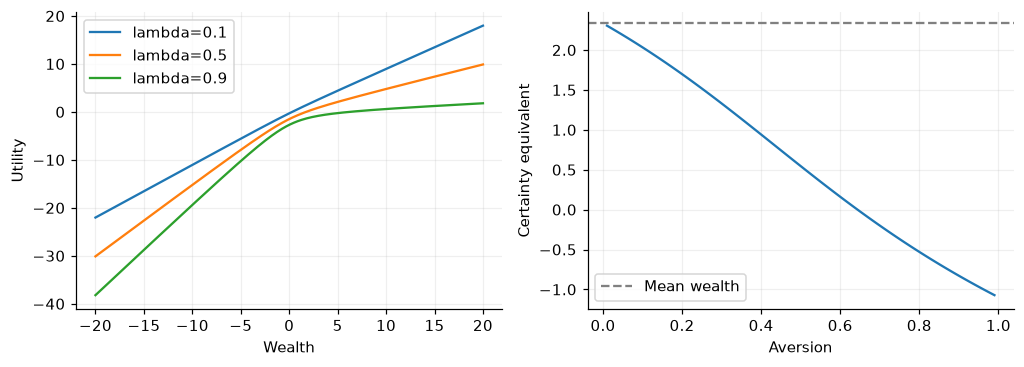

In [3]:
x = np.linspace(-20, 20, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for aversion in (.1, .5, .9):
    model = utility.SmoothUtility(aversion, 3.)
    axes[0].plot(x, model(x), label=f'lambda={aversion}')
a = np.linspace(.01, .99, 80)
axes[1].plot(a, [utility.certainty_equivalent(wealth, utility.SmoothUtility(z, 3.)) for z in a])
axes[1].axhline(wealth.mean(), color='grey', linestyle='--', label='Mean wealth')
axes[0].set(xlabel='Wealth', ylabel='Utility'); axes[0].legend()
axes[1].set(xlabel='Aversion', ylabel='Certainty equivalent'); axes[1].legend(); plt.show()

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.